In [1]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.insert(0, '..')  # nbs/notebook_cache.py
from notebook_cache import NotebookCache

cache = NotebookCache.here(also=['01_canvas'])  # the same step's results notebook: same package

# Verne, step 01: the camera canvas, what changed and how shapes flow

The results (training, rollouts, scores): `01_canvas.ipynb` (3 training seeds × 50: T1 59 and 48/150, step 0 56 and 54; T1-wide 18 and 21/150, step 0 4 and 3). Step 0's walkthrough: `00_explained.ipynb`.

Only what's new since step 0: the input. The top and wrist cameras sit side by side as one wide image, as in Verne's `build_canvas` (`../verne-v0.5/src/verne/transforms.py`). Everything after the patches is step 0's, just with more tokens.

```-
the policy, one call:   [top | wrist] [3, 128, 256] + joints [8]  ->  next 16 actions [16, 8]
step 0 was:              top          [3, 128, 128] + joints [8]  ->  next 16 actions [16, 8]
```

### setup: T1 data and the trained step 01 weights, training seed 0 (read from `01_canvas`'s cache, nothing retrains)


In [2]:
import numpy as np
import torch
from frozendict import frozendict

import dream_robot.policies.verne as verne
from dream_robot.policies.verne.data import canvas, load_cameras, load_table, to_gpu

NAME = 'pick_place_cube_n100'

In [3]:
@cache
def table():
    state, action, episode = load_table(NAME)  # [N, 8], [N, 8], [N]
    return frozendict(state=state, action=action, episode=episode)

table: not cached, will compute (or read a matching result from also)


In [4]:
@cache
def cameras():
    top, wrist = load_cameras(NAME)  # [N, 3, 128, 128] uint8 each, a few minutes the first time
    return frozendict(top=top, wrist=wrist)

cameras: not cached, will compute (or read a matching result from also)


In [5]:
data, cams = table(), cameras()
val = np.random.default_rng(0).permutation(100)[:10]  # as dreamzero / uwm2
rest = np.setdiff1d(np.arange(100), val)
split = frozendict(val=val, labelled=np.random.default_rng(1).choice(rest, 10, replace=False))
demos = to_gpu(
    canvas(cams['top'], cams['wrist']),
    data['state'],
    data['action'],
    data['episode'],
    split['labelled'],
)
print({k: len(v) for k, v in split.items()}, tuple(demos.canvas.shape))

table: read from /root/dream-robot/cache/nbs/verne/01_canvas
cameras: read from /root/dream-robot/cache/nbs/verne/01_canvas
{'val': 10, 'labelled': 10} (21295, 3, 128, 256)


In [6]:
import dream_robot.policies.verne as verne


@cache
def train_run(steps: int, seed: int):
    return verne.train.train(demos, split['labelled'], split['val'], steps, seed=seed)

train_run: not cached, will compute (or read a matching result from also)


In [7]:
weights = train_run(20000, 0)['weights']  # training seed 0
net = verne.model.Verne().cuda().eval()
net.load_state_dict(weights)
print(f'{sum(p.numel() for p in net.parameters()) / 1e6:.2f}M params')

train_run: read from /root/dream-robot/cache/nbs/verne/01_canvas
step      0   train 2.224   val 2.868
step   1000   train 0.164   val 0.193
step   2000   train 0.079   val 0.165
step   3000   train 0.078   val 0.219
step   4000   train 0.043   val 0.183
step   5000   train 0.046   val 0.201
step   6000   train 0.068   val 0.231
step   7000   train 0.037   val 0.219
step   8000   train 0.039   val 0.203
step   9000   train 0.025   val 0.219
step  10000   train 0.039   val 0.245
step  11000   train 0.034   val 0.256
step  12000   train 0.033   val 0.224
step  13000   train 0.033   val 0.273
step  14000   train 0.043   val 0.265
step  15000   train 0.034   val 0.251
step  16000   train 0.027   val 0.272
step  17000   train 0.021   val 0.251
step  18000   train 0.017   val 0.267
step  19000   train 0.036   val 0.267
step  20000   train 0.012   val 0.304
3.68M params


### 1. the canvas: two cameras, one image

Two moments of one labelled demo: its first frame, and the step where the expert first commands close.


In [8]:
ep = split['labelled'][0]
rows = np.flatnonzero(data['episode'] == ep)  # this demo's frames in the table
grasp = rows[np.argmax(data['action'][rows, 7] < 0.5)]  # first commanded close
moments = {'start': rows[0], 'grasp': grasp}
for name, i in moments.items():
    c = demos.canvas[i]
    print(
        f'{name:5s} row {i:5d} (step {i - rows[0]:3d}):  canvas {tuple(c.shape)} {c.dtype}, values {c.min().item()}..{c.max().item()}'
    )

start row  6591 (step   0):  canvas (3, 128, 256) torch.uint8, values 0..255
grasp row  6652 (step  61):  canvas (3, 128, 256) torch.uint8, values 0..255


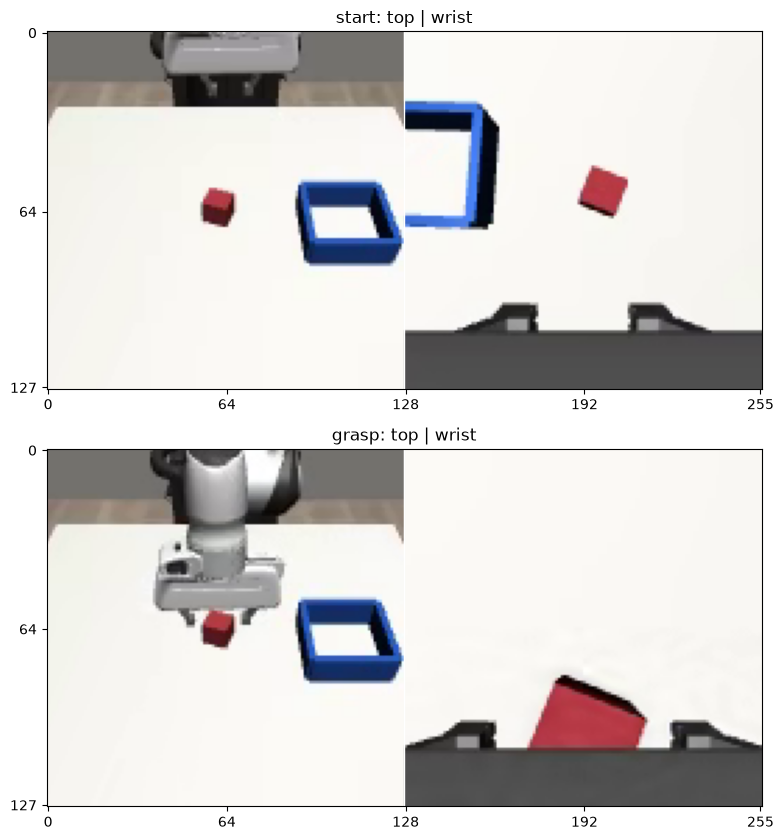

In [9]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 1, figsize=(8, 8.5))
for ax, (name, i) in zip(axs, moments.items()):
    ax.imshow(demos.canvas[i].permute(1, 2, 0).cpu().numpy())
    ax.axvline(127.5, color='w', lw=1)
    ax.set(title=f'{name}: top | wrist', xticks=[0, 64, 128, 192, 255], yticks=[0, 64, 127])
fig.tight_layout()

**One canvas is [3, 128, 256] uint8: the top camera on the left half, the wrist camera on the right.** Nothing marks the seam; the model only learns where it is through the positions.

- Start: in the top view the cube is a few pixels, about 1-2 of 64 patches. In the wrist view it's already bigger, and the fingers sit along the bottom edge.
- Grasp (step 61): from above, the gripper is over the cube; from the wrist, the cube fills the gap between the fingers, about 4-6 patches. That close-up is what the wrist view adds, and why it might help the last few centimetres.
- Same as Verne's `build_canvas` in layout; Verne's is 256 × 768 (3 cameras), fed through a VAE, not raw pixels.


### 2. the eyes, part 1: a canvas becomes 129 tokens

Same cut as step 0 (`see` in `model.py`): 16 × 16 pixel patches, each one linear layer to 256 numbers, the joints token in front, a learned position added to each.


In [10]:
from einops import rearrange

frames = demos.canvas[list(moments.values())].float() / 127.5 - 1  # [2, 3, 128, 256] in -1..1
patches = rearrange(frames, 'b c (h p) (w q) -> b (h w) (p q c)', p=verne.model.P, q=verne.model.P)
s = (demos.state[list(moments.values())] - demos.s_mean) / demos.s_std
with torch.no_grad():
    tokens = torch.cat([net.state_in(s)[:, None], net.patch_in(patches)], 1) + net.video_pos
print(
    f'patches {tuple(patches.shape)}: {128 // 16} rows x {256 // 16} cols, 16*16*3 = 768 numbers each'
)
print(
    f'tokens  {tuple(tokens.shape)}: joints + 128 patches; positions {tuple(net.video_pos.shape)}'
)
print(f'step 0 had 1 + 64 = 65 tokens')

patches (2, 128, 768): 8 rows x 16 cols, 16*16*3 = 768 numbers each
tokens  (2, 129, 256): joints + 128 patches; positions (1, 129, 256)
step 0 had 1 + 64 = 65 tokens


In [11]:
@lambda f: f()
def probe():
    print(f'{moments=}')
    print(f'{demos.canvas.shape=}')
    print(f'{128/16=}')
    print(f'{256/16=}')
    print(f'{8*16=}')
    print(f'{16*16*3=}')
    print(f'{net.state_in(s)[:, None].shape=}')
    print(f'{net.patch_in(patches).shape=}')

moments={'start': np.int64(6591), 'grasp': np.int64(6652)}
demos.canvas.shape=torch.Size([21295, 3, 128, 256])
128/16=8.0
256/16=16.0
8*16=128
16*16*3=768
net.state_in(s)[:, None].shape=torch.Size([2, 1, 256])
net.patch_in(patches).shape=torch.Size([2, 128, 256])


In [12]:
def cube_patches(canvas) -> np.ndarray:
    # [3, 128, 256] uint8 -> [8, 16] count of red (cube) pixels in each patch
    r, g, b = canvas.int().cpu().numpy()
    red = (r > 120) & (g < 80) & (b < 80)
    return red.reshape(8, 16, 16, 16).sum((1, 3))


for name, i in moments.items():
    n = cube_patches(demos.canvas[i])
    print(
        f'{name:5s}: cube in top half {(n[:, :8] > 0).sum():2d} patches ({n[:, :8].sum():4d} px), '
        f'wrist half {(n[:, 8:] > 0).sum():2d} patches ({n[:, 8:].sum():4d} px)'
    )

start: cube in top half  2 patches (  48 px), wrist half  1 patches ( 162 px)
grasp: cube in top half  4 patches (  46 px), wrist half  6 patches ( 594 px)


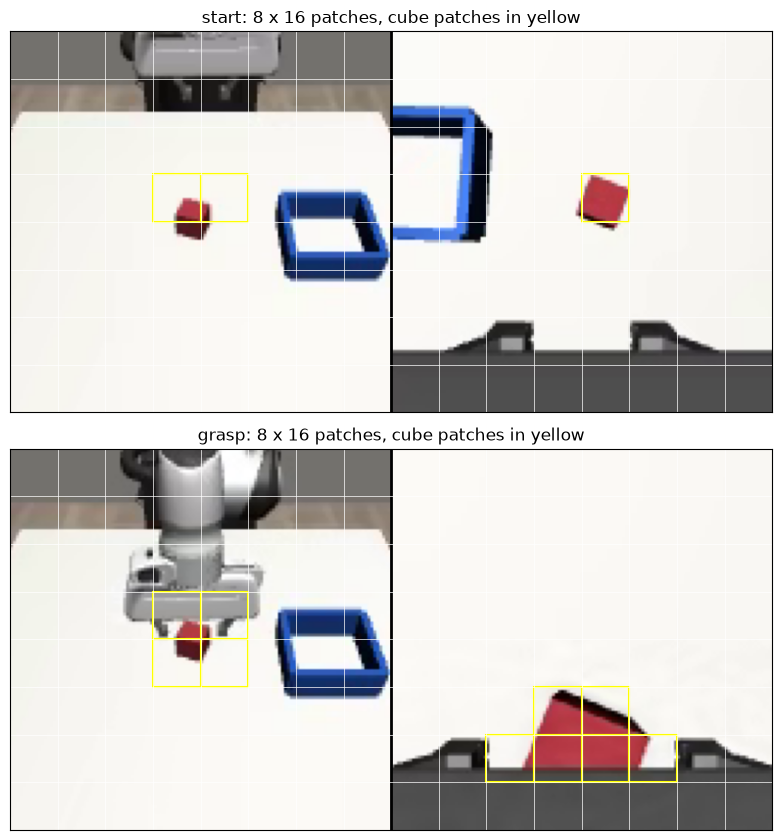

In [13]:
fig, axs = plt.subplots(2, 1, figsize=(8, 8.5))
for ax, (name, i) in zip(axs, moments.items()):
    ax.imshow(demos.canvas[i].permute(1, 2, 0).cpu().numpy())
    for k in range(1, 16):
        ax.axvline(16 * k - 0.5, color='w' if k != 8 else 'k', lw=0.5 if k != 8 else 2)
    for k in range(1, 8):
        ax.axhline(16 * k - 0.5, color='w', lw=0.5)
    for row, col in zip(*np.nonzero(cube_patches(demos.canvas[i]))):
        ax.add_patch(
            plt.Rectangle((16 * col - 0.5, 16 * row - 0.5), 16, 16, fill=False, ec='yellow', lw=1.5)
        )
    ax.set(title=f'{name}: 8 x 16 patches, cube patches in yellow', xticks=[], yticks=[])
fig.tight_layout()

**Each sample is now 129 tokens of 256 numbers** (step 0: 65): token 0 is the joints, tokens 1-128 the patches, 64 from each camera. Each patch is 768 pixel numbers squeezed through the same `patch_in` layer whichever camera it came from; only its learned position says which camera and where.

- The cube in red pixels (counted per patch, yellow boxes): start: top 2 patches, 48 px; wrist 1 patch, 162 px. Grasp: top 4 patches, 46 px; wrist 6 patches, 594 px.
- So at the grasp the wrist half shows the cube with ~13× the pixels of the top half. Whether the model uses it is another question: on T1 the canvas scores like step 0 (59 vs 56/150); on T1-wide, where the cube moves, 18 vs 4/150.
- Order note: the flatten goes row by row across the whole canvas, so each row of 16 tokens is 8 top patches then 8 wrist patches; top and wrist tokens are interleaved, not two blocks. Attention doesn't care about order, only positions do.


### 3. the eyes, part 2: four video layers, and what they save

Same layers as step 0 (`see`): the 129 tokens go through 4 layers; each layer saves its keys and values for the action side.


In [14]:
with torch.no_grad():
    kvs = net.see(frames, s)
for n, (k, v) in enumerate(kvs):
    print(
        f'video layer {n}: keys {tuple(k.shape)}, values {tuple(v.shape)}  [B, heads, tokens, head dim]'
    )

video layer 0: keys (2, 4, 129, 32), values (2, 4, 129, 32)  [B, heads, tokens, head dim]
video layer 1: keys (2, 4, 129, 32), values (2, 4, 129, 32)  [B, heads, tokens, head dim]
video layer 2: keys (2, 4, 129, 32), values (2, 4, 129, 32)  [B, heads, tokens, head dim]
video layer 3: keys (2, 4, 129, 32), values (2, 4, 129, 32)  [B, heads, tokens, head dim]


**Each video layer saves keys and values [B, 4 heads, 129 tokens, 32]**, step 0's [B, 4, 65, 32] with the wrist's 64 tokens added. The video side never sees the actions, so this runs once per chunk.


### 4. the hands: where the action tokens look

The action side is step 0's. What's new is what it can look at: at each layer, 16 action queries against 129 video keys + their own 16 = 145 keys. Below, each layer's attention weight summed over 4 groups: joints token, top patches, wrist patches, own action tokens. Averaged over heads, the 16 queries, and 32 noise draws at τ = 0.9 (nearly clean), for both moments.


In [15]:
from einops import einsum

col = np.arange(128) % 16  # canvas column of patch j: 0-7 top, 8-15 wrist
groups = {
    'joints': [0],
    'top': list(1 + np.flatnonzero(col < 8)),
    'wrist': list(1 + np.flatnonzero(col >= 8)),
    'own': list(range(129, 145)),
}


@torch.no_grad()
def attention_split(i: int, tau: float = 0.9, draws: int = 32) -> np.ndarray:
    # canvas row i -> [layers, groups]: the action queries' attention weight on each group
    frame = (demos.canvas[i].float() / 127.5 - 1)[None].expand(draws, -1, -1, -1)
    st = ((demos.state[i] - demos.s_mean) / demos.s_std)[None].expand(draws, -1)
    end = rows[-1] if i in rows else i
    acts = (demos.action[np.minimum(i + np.arange(16), end)] - demos.a_mean) / demos.a_std
    torch.manual_seed(0)
    noise = torch.randn(draws, 16, 8, device='cuda')
    x = (1 - tau) * noise + tau * acts[None]
    t = torch.full((draws,), tau, device='cuda')
    y = net.action_in(x) + net.action_pos + net.time_in(t[:, None])[:, None]
    out = []
    for block, (kv, vv) in zip(net.action, net.see(frame, st)):
        q, k, v = block.qkv_of(y)
        keys = torch.cat([kv, k], 2)  # [draws, heads, 145, 32]
        w = (einsum(q, keys, 'b h s d, b h t d -> b h s t') / keys.shape[-1] ** 0.5).softmax(-1)
        out.append([w[..., g].sum(-1).mean().item() for g in groups.values()])
        y = block.finish(y, q, keys, torch.cat([vv, v], 2))
    return np.array(out)

In [16]:
even = np.array([len(g) for g in groups.values()]) / 145
print(f'{"":14s}' + ''.join(f'{g:>8s}' for g in groups))
print(f'{"even (n/145)":14s}' + ''.join(f'{e:8.2f}' for e in even))
for name, i in moments.items():
    for n, row in enumerate(attention_split(i)):
        print(f'{name:5s} layer {n}  ' + ''.join(f'{w:8.2f}' for w in row))

                joints     top   wrist     own
even (n/145)      0.01    0.44    0.44    0.11
start layer 0      0.08    0.39    0.46    0.07
start layer 1      0.38    0.14    0.23    0.25
start layer 2      0.33    0.10    0.23    0.34
start layer 3      0.37    0.04    0.05    0.54
grasp layer 0      0.10    0.35    0.49    0.06
grasp layer 1      0.19    0.20    0.46    0.15
grasp layer 2      0.44    0.04    0.37    0.15
grasp layer 3      0.38    0.07    0.11    0.44


**The action side leans on the joints token, barely on the top camera, and turns to the wrist at the grasp.** One demo, two moments, training seed 0: a description, not proof of use (attention weight is not influence).
- Joints: 1 token of 145, yet 0.33-0.44 of the weight in layers 1-3 (30-40× its even share), at both moments.
- Top patches: near even in layer 0 only; 0.04-0.10 in layers 2-3 (even 0.44).
- Wrist patches: at the start 0.23 → 0.23 → 0.05 over layers 1-3; at the grasp 0.46 and 0.37 in layers 1-2. The close-up draws more attention when the cube is between the fingers.
- Fits the probes: on T1 the model mostly plays back a path from the joints (the cube barely moves), and the image matters little.

### 5. wrap-up: what step 01 buys, and where it fails

**Buys:** a second view in the same input path, Verne's way: one wide image, one patch embedding, nothing camera-specific but the positions. At the grasp the wrist shows the cube with ~13× the pixels of the top view, and the action side does look there then.

**Fails, on T1:** 59/150 and 48/150 against step 0's 56 and 54 (3 training seeds × 50 rollouts), mostly no_grasp: no gain. Held-out loss ends worse (seed 0: 0.304 vs 0.246) at the same training loss: twice the tokens, the same 10 demos, more to overfit on. The training seed matters more than the step (10 to 30 of 50).

**Buys, on T1-wide (90 demos, cube moves ±10 cm):** 18/150 and 21/150 against step 0's 4 and 3. Only some runs learn to find the cube: the close-point probe gives x slope 0.61 for seed 2, ~0 for seeds 0 and 1, and 0.95 for seed 0 trained on the local GPU (same code, different hardware). No step 0 run found it.

**For the next boxes:** 02 (VAE latents) shrinks each half to compact, meaningful cells instead of 768 raw pixel numbers per patch; that went 24 → 34/40 in WAMz. The wrist view pays off where the cube moves (T1-wide), but only in runs that find it; 02 may make the cube easier to find, and 11 (cosine LR + EMA) may make runs find it more often.
